# Pipeline review — field 860

A row is a ZTF deep-reference object with its PS1 DR2 stack match at 1″, or an unmatched PS1 object; bands g, r, i.
Sections follow the pipeline (README, "The filtering pipeline at a glance"): **1 inputs** → per band, every object:
**2 quality** (each survey's side usable, or X) → **3 detection** (D / L / U) → **4 comparison and sorting** (≥ 2
comparable bands of one kind → `in_both` / `in_ztf` / `in_pstarr`, else not comparable) → per catalog, object-wide:
**5 confident** → **6 population** → **7 calibrate** (recovery limits, envelope, on what is left) → **8 interesting**
→ **9 results**. A dropped band stays dropped; an object leaves as soon as fewer than two bands remain.
The pipeline runs in memory below (`ff.prepare_field` + `ff.filter_prepared`, ~2 min). Code: `Source_Analysis/filter_field.py`.

In [ ]:
import os, sys, io, warnings; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import OrderedDict
from IPython.display import display
from scipy.stats import norm
from scipy.spatial import cKDTree
from astropy.nddata import Cutout2D
from astropy.coordinates import SkyCoord, match_coordinates_sky
from astropy.visualization import simple_norm
import astropy.units as u
from matplotlib.lines import Line2D
from Extracting.images import load_refimg
from Extracting.ztf_products import refimg_path
from Extracting import ps1_skycells, ps1_stack
from Source_Analysis import filter_field as ff
from source_db.cutouts.render import DEFAULT_STRETCH, DEFAULT_PERCENT
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
FIELD, D = 860, '../Data'
CUTS = ff.Cuts()
print(CUTS)
base = ff.prepare_field(FIELD, D)
src, env, cands, wfs = ff.filter_prepared(base, CUTS, verbose=False)
del base
CAT = {name: k for k, name in ff.CATALOG.items()}
NAMES = list(CAT)

Cuts(bright_star_mask=True, sharp_max=0.5, sharp_point_only=True, ps1_sky_max=1e-07, ps1_min_nframes=4, isolation_arcsec=3.0, neighbour_kron=True, snr_keep=None, envelope_clip_mad=5.0)


## 1. Inputs

In [ ]:
n = {'ZTF objects': int((src.ztf_idx >= 0).sum()), 'PS1 objects': int((src.ps1_idx >= 0).sum()), 'matched at 1″': int(((src.ztf_idx >= 0) & (src.ps1_idx >= 0)).sum())}
for b in 'gri':
    n[f'ZTF {b} detections'] = int(src[f'{b}_ztf_det'].sum()); n[f'PS1 {b} detections'] = int(src[f'{b}_ps1_detected'].sum())
display(pd.Series(n, name='count').to_frame().T)

,ZTF objects,PS1 objects,matched at 1″,ZTF g detections,PS1 g detections,ZTF r detections,PS1 r detections,ZTF i detections,PS1 i detections
count,6265850,2296477,1327471,2387795,878518,3231242,971621,2940043,1388896


## How to read the filter tables and cutouts

Two stages, each a waterfall (`wfs[name]`, steps tagged with their group, `ff.GROUPS`):

- **Shared stage** (`wfs['all']`) — every object with ≥ 2 measured bands goes through the `quality` steps, then the
  `comparison` step (`>= 2 comparable bands of one kind`). Comparable objects get a catalog.
- **Catalog stage** (`wfs['in_both']`, `wfs['in_ztf']`, `wfs['in_pstarr']`) — each catalog runs its `confident` and
  `population` steps on its comparable objects, then `interesting`.

Each table has one block of columns per population (`all` for the shared stage), with the block's starting count in its header:

| column | meaning |
|---|---|
| **after** | objects still in the chain after this step (steps in order; an object stays while ≥ 2 bands survive) |
| **removed** | objects this step took out of the chain |
| **cum. removed %** | share of the stage's start gone by this step |
| **alone %** | share of the start that would *pass* if this were the only step applied (100 − alone = its rejection on its own) |
| **unique**, **unique %** | objects that pass every other step of the stage but fail this one — what the chain loses *only* because of this step |

Objects that fail several steps count in neither *alone* nor *unique*, so *unique* sums to less than the total removed.
A `–` means the step is not part of that catalog's chain.

Cutouts (saved under `Data/fields/000860/review/filter_cutouts/<group>/<catalog>.png`, too large to show inline):
random objects a step removes — ZTF reference over PS1 stack in the band the step cuts, 30″, north up; red + the
object, white ○ ZTF objects, orange □ PS1 objects; magnitudes in red, the object's catalog top left, a red ★ if the
step removes it uniquely.

In [ ]:
def two(m, alive0):
    return (sum(m[b].astype(int) for b in 'gri') >= 2) & alive0

def alone_unique(passes, alive0):
    """per step: pass-alone and unique-cut fractions, the uniquely removed objects, and the bands each object fails"""
    pass_all = two({b: np.logical_and.reduce([p[b] for _, _, p in passes]) for b in 'gri'}, alive0)
    out, unique_masks, fail_bands = [], {}, {}
    for i, (g, l, p) in enumerate(passes):
        others = two({b: np.logical_and.reduce([q[b] for j, (_, _, q) in enumerate(passes) if j != i]) for b in 'gri'}, alive0)
        unique = others & ~pass_all
        out.append({'group': g, 'step': l, 'alone': two(p, alive0).sum() / alive0.sum(), 'unique': unique.sum() / alive0.sum(), 'n_unique': int(unique.sum())})
        unique_masks[l] = unique; fail_bands[l] = {b: alive0 & ~p[b] for b in 'gri'}
    return pd.DataFrame(out), unique_masks, fail_bands

def shared_analysis():
    steps = ff.quality_steps(src, src.point_source.values, CUTS)
    start_m = {b: steps[0][2][b] for b in 'gri'}
    alive0 = sum(start_m[b].astype(int) for b in 'gri') >= 2
    passes = [(g, l, {b: start_m[b] & p[b] for b in 'gri'}) for g, l, p in steps[1:]]
    # the chain's comparable step reads the statuses, which already carry the quality failures (X); for alone/unique it
    # is redefined by S/N only: a side at S/N >= 5 in the band
    pure = lambda b: (src[f'{b}_ztf_det'].values & (src[f'{b}_ztf_snr'].values >= ff.SNR_MIN)) | (src[f'{b}_ps1_meas'].values & (src[f'{b}_ps1_snr'].values >= ff.SNR_MIN))
    passes = [(g, l, {b: start_m[b] & pure(b) for b in 'gri'} if g == 'comparison' else p) for g, l, p in passes]
    return (alive0.sum(), *alone_unique(passes, alive0))

def catalog_analysis(k):
    rows = src.catalog.values == k
    start_m = {b: rows & (src[f'{b}_cat'].values >= 0) for b in 'gri'}
    alive0 = sum(start_m[b].astype(int) for b in 'gri') >= 2
    passes = [('confident', l, {b: start_m[b] & ok for b in 'gri'}) for l, ok in ff.real_checks(src, k, CUTS)]
    passes += [('population', 'Gaia: no proper motion at 5σ', {b: start_m[b] & ff.gaia_population_ok(src)[0] for b in 'gri'}),
               ('population', 'Gaia: no parallax at 5σ', {b: start_m[b] & ff.gaia_population_ok(src)[1] for b in 'gri'})]
    return (alive0.sum(), *alone_unique(passes, alive0))

analysis = {'all': shared_analysis(), **{name: catalog_analysis(k) for name, k in CAT.items()}}

def removed_in_chain(name, step):
    """objects the chain of `name` loses at `step`: in before it, out after it"""
    wf = wfs[name]; i = wf.steps.index(step)
    before = np.logical_or.reduce(list(wf.mask(i - 1).values())); after = np.logical_or.reduce(list(wf.mask(i).values()))
    return before & ~after

def group_table(group):
    """one block of columns per population ('all' for the shared stage); '–' where a step is not in that chain"""
    names = ['all'] if group in ('quality', 'comparison') else NAMES
    order = []                                                         # the group's steps, in chain order, over all populations
    for name in names:
        for l in analysis[name][1].step[analysis[name][1].group == group]:
            if l not in order: order.append(l)
    parts = []
    for name in names:
        n0, tab = analysis[name][:2]
        after = wfs[name].stats.set_index('step').objects
        t = tab[tab.group == group].set_index('step').reindex(order)
        removed = after.shift(1) - after
        cum = 100 * (1 - after / after.iloc[0])
        fmt = lambda s, f: s.reindex(order).map(lambda v: '–' if pd.isna(v) else f(v))
        pct = lambda v: '0' if v == 0 else (f'{v:.1e}' if v < 0.01 else f'{v:.2f}')
        parts.append(pd.DataFrame({'after': fmt(after, lambda v: f'{int(v):,}'), 'removed': fmt(removed, lambda v: f'{int(v):,}'),
                                   'cum. removed %': fmt(cum, lambda v: f'{v:.1f}'), 'alone %': fmt(100 * t.alone, lambda v: f'{v:.1f}'),
                                   'unique': fmt(t.n_unique, lambda v: f'{int(v):,}'), 'unique %': fmt(100 * t.unique, pct)}, index=order))
    return pd.concat(parts, axis=1, keys=[f'{n} (start {analysis[n][0]:,})' for n in names])

# ---- cutouts: ZTF reference over PS1 stack, in the band the step cuts
from astropy.io import fits
from astropy.wcs import WCS
from source_db.cutouts.render import ps1_cutout_url, ps1_linear_flux, _get_fits
from source_db.cutouts.panstarrs import _post as ps1_filenames
REVIEW_DIR = f'{D}/fields/{FIELD:06d}/review'; PS1_CACHE = f'{REVIEW_DIR}/ps1_stamps'; os.makedirs(PS1_CACHE, exist_ok=True)
_refs = OrderedDict()
def ref_image(ccd, qid, b='r'):
    key = (ccd, qid, b)
    if key not in _refs:
        if len(_refs) >= 12: _refs.popitem(last=False)
        _refs[key] = load_refimg(refimg_path(f'{D}/ztf_data', FIELD, *key))
    return _refs[key]
cosd = np.cos(np.radians(src.dec.median()))
objs = {'ZTF': src[src.ztf_idx >= 0], 'PS1': src[src.ps1_idx >= 0]}
trees = {k: cKDTree(np.c_[v.ra.values * cosd, v.dec.values]) for k, v in objs.items()}

def ps1_stamp(r, b, files, size):
    path = os.path.join(PS1_CACHE, f'{r.ra:.6f}_{r.dec:+.6f}_{b}_{size}.fits')
    if not os.path.exists(path):
        name = files.get((round(r.ra, 6), round(r.dec, 6), b))
        raw = _get_fits(ps1_cutout_url(r.ra, r.dec, name, int(size / 0.25))) if name else None
        if not raw: return None, None
        open(path, 'wb').write(raw)
    hdu = fits.open(path)[0]
    return ps1_linear_flux(hdu.data.astype(np.float32), hdu.header), WCS(hdu.header)

def draw(ax, data, wcs, r, b, survey, size, star=False):
    ax.set_xticks([]); ax.set_yticks([])
    if data is None or data.size == 0 or not np.isfinite(data).any():
        ax.text(0.5, 0.5, 'no image', ha='center', va='center', transform=ax.transAxes); return
    flip = wcs.pixel_scale_matrix[0, 0] > 0
    data = data[::-1, ::-1] if flip else data
    def pix(ra, dec):
        x, y = wcs.world_to_pixel_values(np.asarray(ra), np.asarray(dec))
        return (data.shape[1] - 1 - x, data.shape[0] - 1 - y) if flip else (x, y)
    ax.imshow(data, origin='lower', cmap='viridis', norm=simple_norm(data, DEFAULT_STRETCH, percent=DEFAULT_PERCENT))
    for (k, o), (col, mk, s) in zip(objs.items(), (('white', 'o', 90), ('orange', 's', 50))):
        hit = o.iloc[trees[k].query_ball_point([r.ra * cosd, r.dec], size * 0.75 / 3600)]
        x, y = pix(hit.ra.values, hit.dec.values); ax.scatter(x, y, s=s, marker=mk, facecolors='none', edgecolors=col, lw=1.1)
    x, y = pix([r.ra], [r.dec]); ax.plot(x, y, '+', color='red', ms=14, mew=1.6)
    ax.set_xlim(-0.5, data.shape[1] - 0.5); ax.set_ylim(-0.5, data.shape[0] - 0.5)
    m = r[f'{b}_ztf_psf'] if survey == 'ZTF' else r[f'{b}_ps1_psf']
    ax.text(0.97, 0.97, f'{survey} {b} ' + (f'{m:.1f}' if np.isfinite(m) else '–'), color='red', fontsize=8, ha='right', va='top', transform=ax.transAxes)
    if star: ax.text(0.97, 0.03, '★', color='red', fontsize=22, ha='right', va='bottom', transform=ax.transAxes)

from astropy.nddata import NoOverlapError
def stamp_pair(ax_z, ax_p, r, b, files, size=30, star=False):
    try:
        im = ref_image(int(r.ccd), int(r.qid), b)
        cut = Cutout2D(im.data, SkyCoord(r.ra * u.deg, r.dec * u.deg), size * u.arcsec, wcs=im.wcs, mode='partial')
        draw(ax_z, cut.data, cut.wcs, r, b, 'ZTF', size, star)
    except (NoOverlapError, FileNotFoundError, ValueError):                 # off the ZTF image (e.g. "ZTF image covers the position")
        draw(ax_z, None, None, r, b, 'ZTF', size, star)
    draw(ax_p, *ps1_stamp(r, b, files, size), r, b, 'PS1', size, star)
    ax_p.set_xlabel(f'{r.ra:.4f} {r.dec:+.4f}   ' + '/'.join(f"{r[f'{x}_ztf_status']}{r[f'{x}_ps1_status']}" for x in 'gri') + f'   cut: {b}', fontsize=7)

# the catalog an object would belong to before any quality check: where its S/N >= 5 measurements are, trusted or not
_z = np.logical_or.reduce([src[f'{b}_ztf_det'].values & (src[f'{b}_ztf_snr'].values >= ff.SNR_MIN) for b in 'gri'])
_p = np.logical_or.reduce([src[f'{b}_ps1_meas'].values & (src[f'{b}_ps1_snr'].values >= ff.SNR_MIN) for b in 'gri'])
pre_catalog = np.select([_z & _p, _z, _p], ['in_both', 'in_ztf', 'in_pstarr'], 'neither')

def cutouts_for_group(group, n=6, seed=0, size=30, catalog=None):
    """one ZTF row over one PS1 row per step of the group: random objects the chain removes at that step, in the band
    the step cuts (object-wide steps: r if measured); a red star marks objects removed uniquely by the step. For the
    shared stage, `catalog` restricts the objects to those whose S/N >= 5 measurements would put them in that catalog"""
    rng = np.random.default_rng(seed)
    names = ['all'] if group in ('quality', 'comparison') else NAMES
    sigma_group = group in ('interesting', 'best')                        # σ steps ('best' only with Cuts.snr_keep): no alone/unique, band = largest |σ|
    steps = []                                                            # the group's steps of the catalog(s) plotted, in chain order
    for name in ([catalog] if (catalog is not None and names != ['all']) else names):
        steps += [l for l, g in zip(wfs[name].steps, wfs[name].groups) if g == group and l not in steps]
    rows_per_step = []
    for l in steps:
        pool = pd.concat([src[removed_in_chain(name, l)].assign(catalog_name=name if name != 'all' else pre_catalog[removed_in_chain(name, l)], analysis_key=name,
                                                               uniquely_removed=False if sigma_group else analysis[name][2][l][removed_in_chain(name, l)])
                          for name in names if l in wfs[name].steps])
        if catalog is not None: pool = pool[pool.catalog_name == catalog]
        rows_per_step.append((l, len(pool), pool.sample(min(n, len(pool)), random_state=int(rng.integers(1 << 30))).sort_values(['ccd', 'qid']) if len(pool) else pool))
    def cut_band(name, l, idx):
        if sigma_group:
            sig = {b: abs(src[f'{b}_sigma'].values[idx]) for b in 'gri' if src[f'{b}_cat'].values[idx] >= 0 and np.isfinite(src[f'{b}_sigma'].values[idx])}
            return max(sig, key=sig.get) if sig else 'r'
        fails = [b for b in 'gri' if analysis[name][3][l][b][idx]]
        measured = [b for b in 'gri' if src[f'{b}_ztf_det'].values[idx] or src[f'{b}_ps1_meas'].values[idx]]
        if group in ('confident', 'population') or len(fails) != 1:
            return 'r' if 'r' in measured else (measured[0] if measured else 'r')
        return fails[0]
    K = len(rows_per_step)
    if K == 0:
        print(f'{group}: no steps of this group in the waterfalls'); return
    fig, axes = plt.subplots(3 * K - 1, n, figsize=(2.6 * n, 2.9 * 2 * K + 0.6 * (K - 1)), squeeze=False,
                             gridspec_kw={'height_ratios': [v for k in range(K) for v in ([1, 1, 0.2] if k < K - 1 else [1, 1])]})
    for k, (l, n_rem, rows) in enumerate(rows_per_step):
        ax_z, ax_p = axes[3 * k], axes[3 * k + 1]
        if k < K - 1:
            for ax in axes[3 * k + 2]: ax.axis('off')
        files = ps1_filenames(rows[['ra', 'dec']]).round({'ra': 6, 'dec': 6}).groupby(['ra', 'dec', 'filter']).filename.first() if len(rows) else {}
        for j, (idx, r) in enumerate(rows.iterrows()):
            b = cut_band(r.analysis_key, l, src.index.get_loc(idx))
            stamp_pair(ax_z[j], ax_p[j], r, b, files, size, star=bool(r['uniquely_removed']))
            ax_z[j].text(0.03, 0.97, r.catalog_name + ('\nσ ' + ' '.join(f"{x}{r[f'{x}_sigma']:+.1f}" for x in 'gri' if np.isfinite(r[f'{x}_sigma'])) if sigma_group else ''),
                         color='red', fontsize=7, ha='left', va='top', transform=ax_z[j].transAxes)
        for j in range(len(rows), n): ax_z[j].axis('off'); ax_p[j].axis('off')
        ax_z[0].set_ylabel(f'{l}\n(removes {n_rem:,})\nZTF', fontsize=8); ax_p[0].set_ylabel('PS1', fontsize=8)
        if len(rows) == 0:
            ax_z[0].axis('on'); ax_z[0].set_xticks([]); ax_z[0].set_yticks([])
            ax_z[0].text(0.5, 0.5, f'"{l}"\nremoves nothing in the chain', transform=ax_z[0].transAxes, ha='center', va='center', fontsize=9)
    plt.tight_layout()
    os.makedirs(f'{REVIEW_DIR}/filter_cutouts/{group}', exist_ok=True)
    out = f'{REVIEW_DIR}/filter_cutouts/{group}/{catalog if catalog is not None else "all"}.png'
    fig.savefig(out, dpi=80); plt.close(fig)                              # too large to view inline: saved, not shown
    print(f'saved {len(rows_per_step)} steps → {os.path.abspath(out)}')

## 2. Quality (per band, per survey: usable or X)

Each check reads one survey's side of one band and asks only whether the data at the position are sound
(`ff.ztf_checks`, `ff.ps1_checks`, combined by `ff.usable_sides`). A side that fails is **X**: nothing on it,
measurement or limit, is compared.

ZTF side
- `ZTF image covers the position` — a non-detection means nothing off the reference image.
- `ZTF: DAOPhot flags = 0`.
- `ZTF: > 5 px from a masked pixel` — at the detection, or at the PS1 position when ZTF's side is a limit.
- `extended: ZTF Kron aperture <= 10% masked` — extended objects only.

PS1 side (without a PS1 object only the first three apply: there PS1's limit stands in)
- `PS1: not in a flagged polar skycell` — the band's row is not from one of MAST's mis-registered polar skycells; without a PS1 object, no skycell covering the position is.
- `PS1: catalog covers the position` — without a PS1 object: not in one of MAST's DR2 missing-data boxes, Dec > −30.
- `PS1: objects within 1' in the band` — without a PS1 object: PS1 measured some object in the band within 1′, so its stack reaches the position.
- `PS1: residual sky <= 1e-07` — Jy/arcsec²: bright-star halos, large galaxies, stack background steps.
- `PS1: stack nFrames >= 4` — PS1's outlier rejection needs enough input frames.
- `PS1: not DEFECT`, `PS1: not PEAK_ON_SPIKE`, `PS1: not ON_SPIKE`, `PS1: not ON_STARCORE`, `PS1: not ON_BURNTOOL`, `PS1: not SATSTAR`, `PS1: not SATSTAR_PROFILE` — one step per flag.
- `PS1: measured in the band` — a flux with a positive error (forced photometry counts).
- `PS1: psfQfPerfect > 0.85`.

The table starts from every object with ≥ 2 measured bands (`>= 2 bands: measured by ZTF or PS1`).

In [ ]:
n_all, n_start = len(src), int(wfs['all'].stats.objects.iloc[0])
print(f'all objects {n_all:,} → with ≥ 2 measured bands {n_start:,} ({100 * (1 - n_start / n_all):.1f}% have a measurement in one band only and are never judged)')
display(group_table('quality'))

all objects 7,234,856 → with ≥ 2 measured bands 2,690,168 (62.8% have a measurement in one band only and are never judged)


all (start 2,690,168)                                                 
                                                          after  removed cum. removed % alone %  unique unique %
ZTF image covers the position                         2,519,075  171,093            6.4    93.6       0        0
ZTF: DAOPhot flags = 0                                2,515,673    3,402            6.5    99.9       0        0
ZTF: > 5 px from a masked pixel                       2,475,989   39,684            8.0    92.0   8,238     0.31
extended: ZTF Kron aperture <= 10% masked             2,420,427   55,562           10.0    97.9  53,105     1.97
PS1: not in a flagged polar skycell                   2,404,928   15,499           10.6    99.3   7,891     0.29
PS1: catalog covers the position                      2,404,928        0           10.6   100.0       0        0
PS1: objects within 1' in the band                    2,404,928        0           10.6   100.0       0        0
PS1: residual sky <= 1e-07                            2,391,049   13,879           11.1    99.4   9,548     0.35
PS1: stack nFrames >= 4                               2,373,719   17,330           11.8    99.1   6,148     0.23
PS1: not DEFECT                                       2,373,133      586           11.8    99.8   2,155     0.08
PS1: not PEAK_ON_SPIKE                                2,372,734      399           11.8    99.7     105  3.9e-03
PS1: not ON_SPIKE                                     2,372,730        4           11.8    99.7       0        0
PS1: not ON_STARCORE                                  2,370,516    2,214           11.9    99.4       0        0
PS1: not ON_BURNTOOL                                  2,370,382      134           11.9   100.0       0        0
PS1: not SATSTAR                                      2,370,117      265           11.9   100.0       0        0
PS1: not SATSTAR_PROFILE                              2,370,117        0           11.9    99.8       0        0
PS1: measured in the band                             2,370,109        8           11.9    99.8       0        0
PS1: psfQfPerfect > 0.85                              2,367,951    2,158           12.0    99.0     655     0.02

In [ ]:
for name in NAMES:
    cutouts_for_group('quality', catalog=name)      # shared stage: objects whose S/N ≥ 5 measurements would put them in `name`

saved 18 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/quality/in_both.png
saved 18 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/quality/in_ztf.png
saved 18 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/quality/in_pstarr.png


**Where PS1 says nothing.** Three PS1 checks judge the position rather than a measurement: MAST's mis-registered
polar skycells (`badcells_near_north_pole_v6.dat`; every magnitude there is −999 while fluxes remain; with or without a
PS1 object), and, without a PS1 object, DR2's missing-catalog regions and positions where PS1 measured nothing in the
band within 1′. Bad skycells are also excluded from both recovery-limit references (section 7).

no PS1 object, no PS1 object measured within 1′: {'g': 0, 'r': 0, 'i': 0}


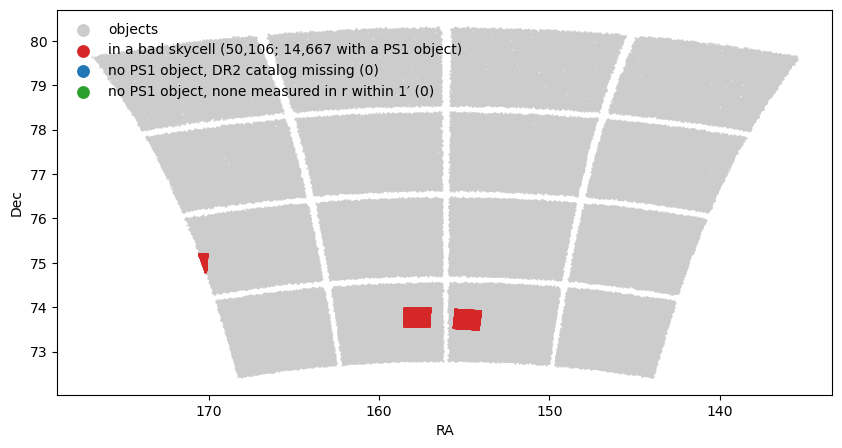

In [ ]:
has = src.ps1_idx.values >= 0
bad, missing = src.ps1_skycell_bad.values, src.ps1_catalog_missing.values
uncovered = {b: ~has & ~src[f'{b}_ps1_covered'].values for b in 'gri'}
print('no PS1 object, no PS1 object measured within 1′:', {b: int(v.sum()) for b, v in uncovered.items()})
fig, ax = plt.subplots(figsize=(10, 5))
s = src.sample(300_000, random_state=0)
ax.scatter(s.ra, s.dec, s=0.3, color='0.8', rasterized=True, label='objects')
ax.scatter(src.ra[bad], src.dec[bad], s=0.3, color='C3', rasterized=True, label=f'in a bad skycell ({bad.sum():,}; {int((bad & has).sum()):,} with a PS1 object)')
ax.scatter(src.ra[missing], src.dec[missing], s=0.3, color='C0', rasterized=True, label=f'no PS1 object, DR2 catalog missing ({missing.sum():,})')
ax.scatter(src.ra[uncovered['r']], src.dec[uncovered['r']], s=0.3, color='C2', rasterized=True, label=f"no PS1 object, none measured in r within 1′ ({uncovered['r'].sum():,})")
ax.invert_xaxis(); ax.set_xlabel('RA'); ax.set_ylabel('Dec'); ax.legend(frameon=False, markerscale=15); plt.show()

## 3. Detection (per band, per usable side: D / L / U)

What each survey has in the band (`ff.detection_status`), independent of quality:
- **D** measured at S/N ≥ 5
- **L** measured below 5 (a ZTF detection under 5; a PS1 measurement, forced fluxes ≤ 0 included): used if brighter than the survey's limit, else the limit
- **U** nothing measured (no ZTF detection, no PS1 object): the survey's completeness limit stands in

`{b}_ztf_status` / `{b}_ps1_status` (`ff.band_status`) are the detection status on usable sides and **X** on the
others. Detection drops nothing, so it is not a waterfall step. Band r, every object: detection status alone, which
sides are usable, then the combined status.

PS1 r detection,D,L,U,All
D,704514,353823,472273,1530610
L,9312,96508,1594812,1700632
U,259037,873283,2871294,4003614
All,972863,1323614,4938379,7234856


PS1 r usable,False,True,All
False,31563,367141,398704
True,156362,6679790,6836152
All,187925,7046931,7234856


PS1 r,D,L,U,X,All
D,645953,325471,416125,41019,1428568
L,8412,91429,1546895,14642,1661378
U,155021,693574,2796910,100701,3746206
X,110223,113908,143010,31563,398704
All,919609,1224382,4902940,187925,7234856


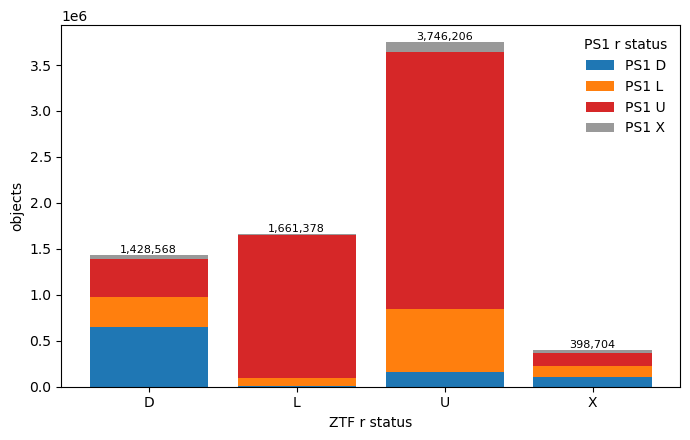

In [ ]:
z, p = ff.detection_status(src, 'r')
z_ok, p_ok = ff.usable_sides(src, 'r', src.point_source.values, CUTS)
assert (np.where(z_ok, z, 'X') == src.r_ztf_status.values).all() and (np.where(p_ok, p, 'X') == src.r_ps1_status.values).all()
with_all = lambda t: t.assign(All=t.sum(axis=1)).pipe(lambda t: pd.concat([t, t.sum().rename('All').to_frame().T]))
display(with_all(pd.crosstab(pd.Series(z, name='ZTF r detection'), pd.Series(p, name='PS1 r detection'))))
display(with_all(pd.crosstab(pd.Series(z_ok, name='ZTF r usable'), pd.Series(p_ok, name='PS1 r usable'))))
ct = pd.crosstab(src.r_ztf_status.rename('ZTF r'), src.r_ps1_status.rename('PS1 r'))
display(with_all(ct))

fig, ax2 = plt.subplots(figsize=(7, 4.5))
bottom = np.zeros(len(ct))
for col, color in zip(ct.columns, ('C0', 'C1', 'C3', '0.6')):
    ax2.bar(ct.index, ct[col], bottom=bottom, label=f'PS1 {col}', color=color); bottom += ct[col].values
for i, tot in enumerate(ct.sum(axis=1)):
    ax2.text(i, tot, f'{tot:,}', ha='center', va='bottom', fontsize=8)
ax2.set_xlabel('ZTF r status'); ax2.set_ylabel('objects'); ax2.legend(frameon=False, title='PS1 r status')
plt.tight_layout(); plt.show()

## 4. Comparison and sorting

Per band, the pair of statuses says what the band compares (`ff.COMPARISON` → `{b}_cat`: 0 two-sided, 1 ZTF vs PS1
limit, 2 PS1 vs ZTF limit, −1 nothing):

| ZTF ╲ PS1 | **D** | **L** | **U** | **X** |
|---|---|---|---|---|
| **D** | ZTF vs PS1 (two-sided) | ZTF vs PS1 limit* | ZTF vs PS1 limit | nothing |
| **L** | PS1 vs ZTF limit* | nothing | nothing | nothing |
| **U** | PS1 vs ZTF limit | nothing | nothing | nothing |
| **X** | nothing | nothing | nothing | nothing |

\* The S/N < 5 measurement (PS1's forced flux, ZTF's catalog value) is compared instead of the limit if it is brighter
than the limit; otherwise the limit.

Per object (`ff.object_catalog`): ≥ 2 two-sided bands → `in_both` (its one-sided bands are dropped) · else ≥ 2 bands
all "ZTF vs PS1 limit" → `in_ztf` · all "PS1 vs ZTF limit" → `in_pstarr` · anything else → **not comparable**, with
`catalog_reason` (fewer than two measured bands, no comparable band, one comparable band, one two-sided band, mixed
one-sided kinds). The shared waterfall ends at `>= 2 comparable bands of one kind`, which keeps exactly the bands the
catalogs start from.

Worked cases, one row per object (cells are ZTF/PS1 status per band):

| # | g | r | i | catalog | outcome |
|:-:|:-:|:-:|:-:|---|---|
| 1 | D/D | D/D | D/D | in_both | g, r, i two-sided |
| 2 | D/D | D/L | D/L | not comparable | one two-sided band |
| 3 | D/D | D/X | D/X | not comparable | one two-sided band |
| 4 | D/L | D/L | D/L | in_ztf | g, r, i: ZTF vs PS1 limit* |
| 4′ | L/D | L/D | L/D | in_pstarr | g, r, i: PS1 vs ZTF limit* |
| 5 | L/D | D/D | D/D | in_both | g dropped · r, i two-sided |
| 6 | U/D | D/D | D/D | in_both | g dropped · r, i two-sided |
| 7 | X/D | D/D | D/D | in_both | g dropped · r, i two-sided |
| 8 | D/D | D/D | D/X | in_both | g, r two-sided · i dropped |
| 9 | L/L | L/L | D/D | not comparable | one two-sided band |
| 10 | D/U | D/U | D/U | in_ztf | g, r, i: ZTF vs PS1 limit |
| 11 | D/U | D/U | U/U | in_ztf | g, r: ZTF vs PS1 limit |
| 12 | D/U | L/U | U/U | not comparable | one comparable band |
| 13 | U/D | U/D | U/D | in_pstarr | g, r, i: PS1 vs ZTF limit |
| 14 | U/D | U/D | U/L | in_pstarr | g, r: PS1 vs ZTF limit |
| 15 | U/D | U/X | U/X | not comparable | one comparable band |
| 16 | U/D | U/D | U/X | in_pstarr | g, r: PS1 vs ZTF limit · i dropped |
| 17 | X/D | X/D | X/D | not comparable | ZTF side unusable (e.g. not covered): no comparable band |
| 18 | L/L | L/L | L/L | not comparable | no comparable band |
| 19 | D/X | D/X | D/X | not comparable | PS1 side X in every band (e.g. a bad polar skycell): no comparable band |
| 20 | D/L | D/L | X/D | in_ztf | g, r: ZTF vs PS1 limit (PS1's i detection has no usable ZTF side) |
| 21 | D/L | U/D | U/D | not comparable | mixed one-sided kinds |

Quality acts before sorting, so a ZTF object whose PS1 match is X in every band is not comparable rather than `in_ztf`.
PS1's BAD_STACK / SUSPECT_STACK are not quality checks: such an object sorts by its statuses and meets the flags in
section 5.

In the table below, *alone* / *unique* of the comparable step count a band as comparable when either side has S/N ≥ 5,
independent of quality (the chain's own step reads the statuses, which already carry the X's).

In [ ]:
display(group_table('comparison'))
for name in NAMES:
    cutouts_for_group('comparison', catalog=name)

all (start 2,690,168)                                                      
                                                  after    removed cum. removed % alone %     unique unique %
>= 2 comparable bands of one kind               799,875  1,568,076           70.3    48.3  1,242,481    46.19

saved 1 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/comparison/in_both.png
saved 1 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/comparison/in_ztf.png
saved 1 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/comparison/in_pstarr.png


### Sorting into catalogs

At the end of the shared stage each object either has ≥ 2 comparable bands of one kind — its catalog — or is not
comparable, with a reason. Objects with a measurement in one band only never enter the shared-stage table.

,"not comparable, by reason"
catalog_reason,
fewer than two measured bands,4544688
no comparable band,726391
one comparable band,710262
one two-sided band,389536
mixed one-sided kinds,64104


,objects,of which ≥ 2 measured bands
catalog,,
not comparable,6434981,1890293
in_both,632453,632453
in_ztf,144687,144687
in_pstarr,22735,22735


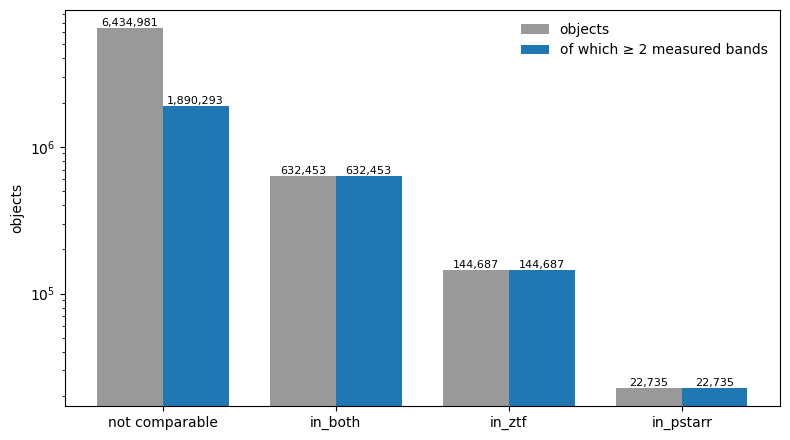

In [ ]:
start = {name: int(wfs[name].stats.objects.iloc[0]) for name in NAMES}
counts = pd.DataFrame({'objects': src.catalog.map({**ff.CATALOG, -1: 'not comparable'}).value_counts()})
counts['of which ≥ 2 measured bands'] = [int(((src.catalog.map({**ff.CATALOG, -1: 'not comparable'}) == k) & (sum(src[f'{b}_ztf_det'] | src[f'{b}_ps1_meas'] for b in 'gri') >= 2)).sum()) for k in counts.index]
display(src.catalog_reason[src.catalog < 0].value_counts().rename('not comparable, by reason').to_frame())
display(counts)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(counts)); w = 0.38
ax1.bar(x - w / 2, counts.objects, w, label='objects', color='0.6')
ax1.bar(x + w / 2, counts['of which ≥ 2 measured bands'], w, label='of which ≥ 2 measured bands', color='C0')
for i, (a_, b_) in enumerate(zip(counts.objects, counts['of which ≥ 2 measured bands'])):
    ax1.text(i - w / 2, a_, f'{a_:,}', ha='center', va='bottom', fontsize=8)
    if b_: ax1.text(i + w / 2, b_, f'{b_:,}', ha='center', va='bottom', fontsize=8)
ax1.set_xticks(x); ax1.set_xticklabels(counts.index); ax1.set_yscale('log'); ax1.set_ylabel('objects'); ax1.legend(frameon=False)
plt.tight_layout(); plt.show()

In [ ]:
# the (ZTF/PS1 per band) status patterns actually seen, per catalog, and what the pipeline does with them (one groupby, not a scan per pattern)
KIND = {0: 'two-sided', 1: 'ZTF vs PS1 limit', 2: 'PS1 vs ZTF limit'}
pat = pd.Series('', index=src.index)
for b in 'gri':
    pat = pat + src[f'{b}_ztf_status'].astype(str) + '/' + src[f'{b}_ps1_status'].astype(str) + ('  ' if b != 'i' else '')
df = pd.DataFrame({'catalog': src.catalog.map({**ff.CATALOG, -1: 'not comparable'}).values, 'pattern': pat.values, 'reason': src.catalog_reason.values,
                   **{f'{b}_cat': src[f'{b}_cat'].values for b in 'gri'}})
g = df.groupby(['catalog', 'pattern'], sort=False)
summary = g.size().rename('objects').to_frame().join(g[['reason', 'g_cat', 'r_cat', 'i_cat']].first())
def outcome(r):
    if r.reason:
        return f'not comparable: {r.reason}'
    used = [(b, KIND[int(r[f'{b}_cat'])]) for b in 'gri' if r[f'{b}_cat'] >= 0]
    return 'kept: ' + ', '.join(b for b, _ in used) + ' ' + ' / '.join(sorted({k for _, k in used}))
summary['outcome'] = summary.apply(outcome, axis=1)
for name in [*NAMES, 'not comparable']:
    t = summary.loc[name].sort_values('objects', ascending=False)
    t['%'] = (100 * t.objects / t.objects.sum()).round(1)
    print(f'--- {name} ({t.objects.sum():,} objects, {len(t)} patterns)')
    display(t[['objects', '%', 'outcome']].rename_axis('pattern (g r i)'))

--- in_both (632,453 objects, 34 patterns)


,objects,%,outcome
pattern (g r i),,,
D/D D/D D/D,371207,58.7,"kept: g, r, i two-sided"
D/L D/D D/D,65521,10.4,"kept: r, i two-sided"
U/L D/D D/D,63411,10.0,"kept: r, i two-sided"
L/L D/D D/D,35807,5.7,"kept: r, i two-sided"
U/D D/D D/D,16599,2.6,"kept: r, i two-sided"
D/D D/L D/D,12730,2.0,"kept: g, i two-sided"
L/D D/D D/D,11239,1.8,"kept: r, i two-sided"
D/D D/D X/D,11110,1.8,"kept: g, r two-sided"
D/X D/D D/D,8992,1.4,"kept: r, i two-sided"


--- in_ztf (144,687 objects, 35 patterns)


,objects,%,outcome
pattern (g r i),,,
U/U D/U D/U,59846,41.4,"kept: r, i ZTF vs PS1 limit"
D/U D/U U/U,17305,12.0,"kept: g, r ZTF vs PS1 limit"
D/U D/U D/U,14185,9.8,"kept: g, r, i ZTF vs PS1 limit"
U/L D/L D/L,14050,9.7,"kept: r, i ZTF vs PS1 limit"
L/U D/U D/U,13823,9.6,"kept: r, i ZTF vs PS1 limit"
D/U U/U D/U,9543,6.6,"kept: g, i ZTF vs PS1 limit"
L/L D/L D/L,3951,2.7,"kept: r, i ZTF vs PS1 limit"
D/U D/U L/U,3766,2.6,"kept: g, r ZTF vs PS1 limit"
D/L D/L D/L,2736,1.9,"kept: g, r, i ZTF vs PS1 limit"


--- in_pstarr (22,735 objects, 85 patterns)


,objects,%,outcome
pattern (g r i),,,
U/L U/D U/D,4612,20.3,"kept: r, i PS1 vs ZTF limit"
U/D U/D U/L,4583,20.2,"kept: g, r PS1 vs ZTF limit"
U/D U/L U/D,3126,13.7,"kept: g, i PS1 vs ZTF limit"
U/D U/D U/D,2960,13.0,"kept: g, r, i PS1 vs ZTF limit"
U/D U/X U/D,916,4.0,"kept: g, i PS1 vs ZTF limit"
...,...,...,...
U/D L/D X/D,1,0.0,"kept: g, r PS1 vs ZTF limit"
L/D L/D D/X,1,0.0,"kept: g, r PS1 vs ZTF limit"
L/D U/D X/D,1,0.0,"kept: g, r PS1 vs ZTF limit"


--- not comparable (6,434,981 objects, 1301 patterns)


,objects,%,outcome
pattern (g r i),,,
U/U L/U U/U,1361850,21.2,not comparable: fewer than two measured bands
L/U U/U U/U,1194834,18.6,not comparable: fewer than two measured bands
U/U U/U L/U,1137076,17.7,not comparable: fewer than two measured bands
U/U D/U U/U,229399,3.6,not comparable: fewer than two measured bands
U/L U/L U/L,228168,3.5,not comparable: no comparable band
...,...,...,...
D/D U/D X/X,1,0.0,not comparable: one two-sided band
D/X X/L U/L,1,0.0,not comparable: no comparable band
U/X D/D X/L,1,0.0,not comparable: one two-sided band


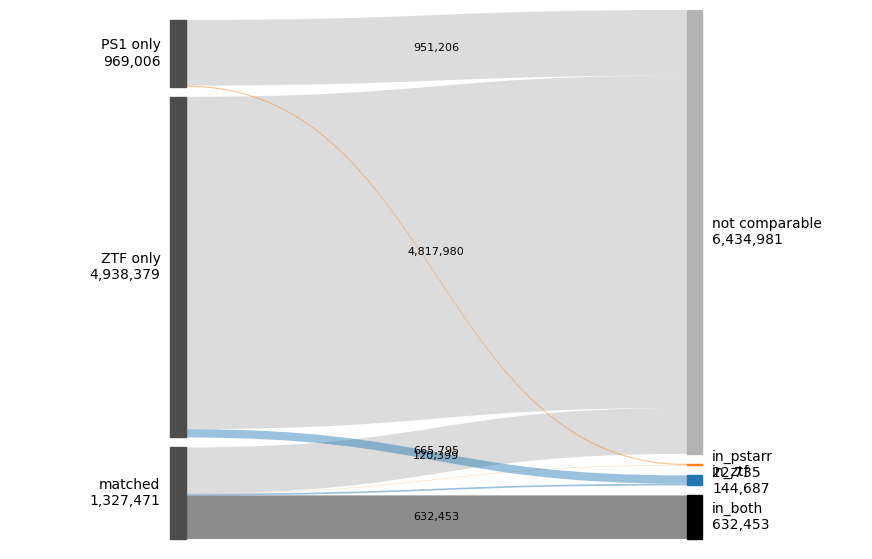

col_0,in_both,in_ztf,in_pstarr,not comparable
row_0,,,,
matched,632453,24288,4935,665795
ZTF only,0,120399,0,4817980
PS1 only,0,0,17800,951206


In [ ]:
# how the match outcome maps onto the catalogs: ribbon width = objects. Only comparable objects get a catalog; a matched
# object is one-sided when the other side never reaches D (sub-5σ forced photometry) and not comparable when it is X everywhere
from matplotlib.path import Path
from matplotlib.patches import PathPatch
left_of = np.where((src.ztf_idx >= 0) & (src.ps1_idx >= 0), 'matched', np.where(src.ztf_idx >= 0, 'ZTF only', 'PS1 only'))
right_of = src.catalog.map({**ff.CATALOG, -1: 'not comparable'}).values
L_ORDER, R_ORDER = ['matched', 'ZTF only', 'PS1 only'], ['in_both', 'in_ztf', 'in_pstarr', 'not comparable']
flow = pd.crosstab(pd.Categorical(left_of, L_ORDER), pd.Categorical(right_of, R_ORDER))
COL = {'in_both': 'k', 'in_ztf': 'tab:blue', 'in_pstarr': 'tab:orange', 'not comparable': '0.7'}
GAP, total = 0.02, flow.values.sum()
def spans(sizes):
    out, y = {}, 0.0
    for k, s in sizes.items():
        out[k] = (y, y + s / total); y += s / total + GAP
    return out
ls, rs = spans(flow.sum(axis=1)), spans(flow.sum(axis=0))
fig, ax = plt.subplots(figsize=(11, 7))
lpos = {k: v[0] for k, v in ls.items()}; rpos = {k: v[0] for k, v in rs.items()}
for l in L_ORDER:
    for r in R_ORDER:
        n = flow.loc[l, r]
        if n == 0: continue
        h = n / total; y0, y1 = lpos[l], rpos[r]
        verts = [(0, y0), (0.5, y0), (0.5, y1), (1, y1), (1, y1 + h), (0.5, y1 + h), (0.5, y0 + h), (0, y0 + h), (0, y0)]
        codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.LINETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
        ax.add_patch(PathPatch(Path(verts, codes), facecolor=COL[r], alpha=0.45, lw=0))
        if h > 0.012: ax.text(0.5, y0 + h / 2 + (y1 - y0) / 2, f'{n:,}', ha='center', va='center', fontsize=8)
        lpos[l] += h; rpos[r] += h
for k, (a, b) in ls.items(): ax.add_patch(plt.Rectangle((-0.03, a), 0.03, b - a, color='0.3')); ax.text(-0.05, (a + b) / 2, f'{k}\n{int(flow.loc[k].sum()):,}', ha='right', va='center', fontsize=10)
for k, (a, b) in rs.items(): ax.add_patch(plt.Rectangle((1, a), 0.03, b - a, color=COL[k])); ax.text(1.05, (a + b) / 2, f'{k}\n{int(flow[k].sum()):,}', ha='left', va='center', fontsize=10)
ax.set_xlim(-0.35, 1.35); ax.set_ylim(-0.02, 1 + GAP * 3); ax.axis('off')
plt.show()
display(flow)

## 5. Confident (object-wide, per catalog)

Is it one real object? Each catalog starts from its comparable objects (`ff.real_checks`), in order:
- `outside bright-star masks` — Gaia G < 16 stars: the Legacy Surveys radius circle and four diffraction-spike boxes.
- `in_ztf`, `in_pstarr`: `no other object within 3"` (either survey, matched or not), `outside every brighter object's Kron aperture`.
- `ZTF: S/N²-weighted |sharp| <= 0.5 (point sources)`.
- `in_both`, `in_pstarr` (PS1's side is a measurement): `PS1: nStackDetections >= 2`, `PS1: not BAD_STACK`,
  `PS1: not SUSPECT_STACK` — PS1's own verdict on its detections. `in_ztf` gets none of the three: there PS1's side is a limit.

In [ ]:
display(group_table('confident'))

in_both (start 632,453)                                                 in_ztf (start 144,687)                                                  \
                                                                    after removed cum. removed % alone %  unique unique %                  after removed cum. removed % alone %  unique unique %   
outside bright-star masks                                         597,413  35,040            5.5    94.5  24,795     3.92                115,247  29,440           20.3    79.7  11,361     7.85   
ZTF: S/N²-weighted |sharp| <= 0.5 (point sources)                 597,235     178            5.6   100.0      97     0.02                 63,353      47           56.2    95.4      47     0.03   
PS1: nStackDetections >= 2                                        593,917   3,318            6.1    99.4   3,079     0.49                      –       –              –       –       –        –   
PS1: not BAD_STACK                                                590,831   3,086            6.6    99.5   2,735     0.43                      –       –              –       –       –        –   
PS1: not SUSPECT_STACK                                            590,816      15            6.6   100.0      10  1.6e-03                      –       –              –       –       –        –   
no other object within 3"                                               –       –              –       –       –        –                 70,681  44,566           51.1    58.8  26,273    18.16   
outside every brighter object's Kron aperture                           –       –              –       –       –        –                 63,400   7,281           56.2    75.8   5,869     4.06   

                                                  in_pstarr (start 22,735)                                                 
                                                                     after removed cum. removed % alone % unique unique %  
outside bright-star masks                                           19,619   3,116           13.7    86.3    264     1.16  
ZTF: S/N²-weighted |sharp| <= 0.5 (point sources)                    5,060      53           77.7    99.2     40     0.18  
PS1: nStackDetections >= 2                                           3,369   1,691           85.2    65.8  1,670     7.35  
PS1: not BAD_STACK                                                   3,041     328           86.6    94.1    327     1.44  
PS1: not SUSPECT_STACK                                               3,039       2           86.6    99.9      2  8.8e-03  
no other object within 3"                                            5,945  13,674           73.9    30.3  3,002    13.20  
outside every brighter object's Kron aperture                        5,113     832           77.5    49.1    243     1.07

In [ ]:
for name in NAMES:
    cutouts_for_group('confident', catalog=name)

saved 5 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/confident/in_both.png
saved 4 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/confident/in_ztf.png
saved 7 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/confident/in_pstarr.png


## 6. Population

No Gaia proper motion or parallax at 5σ.

In [ ]:
display(group_table('population'))
for name in NAMES:
    cutouts_for_group('population', catalog=name)
GAIA = 'Gaia: no parallax at 5σ'
reach = {name: wfs[name].mask(wfs[name].steps.index(GAIA)) for name in NAMES}

in_both (start 632,453)                                                  in_ztf (start 144,687)                                                in_pstarr (start 22,735)  \
                                               after  removed cum. removed % alone %  unique unique %                  after removed cum. removed % alone % unique unique %                    after   
Gaia: no proper motion at 5σ                 471,763  119,053           25.4    79.6  55,271     8.74                 62,870     483           56.5    98.9    281     0.19                    3,026   
Gaia: no parallax at 5σ                      470,687    1,076           25.6    88.8   1,076     0.17                 62,866       4           56.6    99.4      4  2.8e-03                    3,025   

                                                                             
                             removed cum. removed % alone % unique unique %  
Gaia: no proper motion at 5σ      13           86.7    94.3      5     0.02  
Gaia: no parallax at 5σ            1           86.7    96.1      1  4.4e-03

saved 2 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/population/in_both.png
saved 2 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/population/in_ztf.png
saved 2 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/population/in_pstarr.png


## 7. Calibrate (on what is left)

### Recovery limits

A survey's limit in a band is the magnitude at which it recovers 90% of the other survey's objects that would reach
this point on their own side (`ff.completeness_references`): the reference survey's quality and confident checks,
S/N ≥ 5 in ≥ 2 bands, Gaia, outside bad skycells. Recovery = a measurement in the band at the 1″ match (ZTF: a
DAOPhot detection at any S/N; PS1: a detection or forced flux > 0). Per ZTF quadrant, in PSF and in Kron magnitude,
capped at the nominal depth (ZTF MAGLIM; PS1 stack depth from nFrames). Thick: the clean reference the limit is
measured on; thin: every detection, unconditioned.

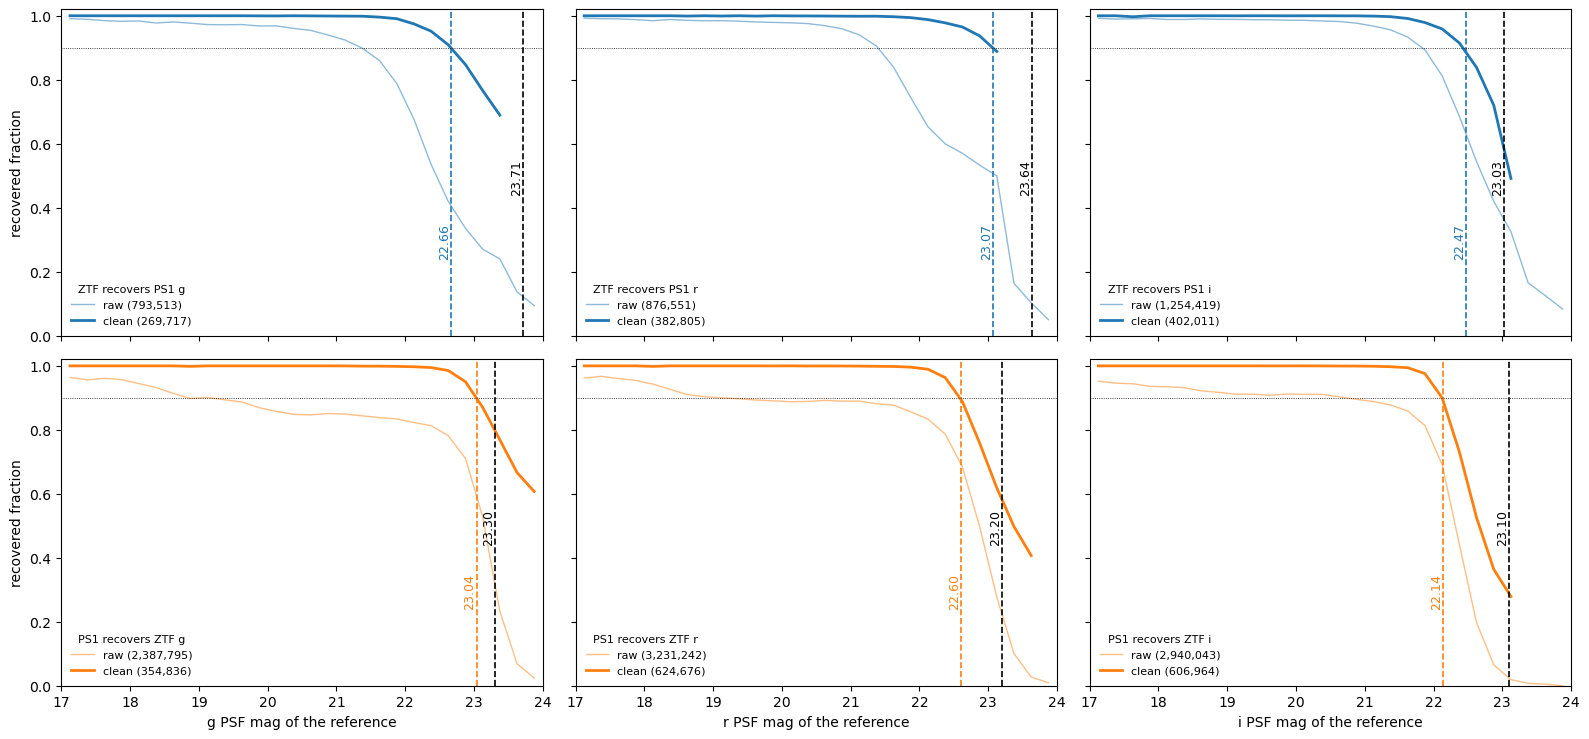

median    min    max  cap (median)
band survey mag                                     
g    ZTF    psf    22.67  22.28  22.83         23.71
            kron   22.70  22.28  23.39         23.71
     PS1    psf    23.06  22.80  23.25         23.20
            kron   23.15  22.80  23.30         23.20
r    ZTF    psf    23.07  22.78  23.07         23.64
            kron   23.63  23.25  23.75         23.64
     PS1    psf    22.61  22.38  22.91         23.10
            kron   22.52  22.24  23.10         23.10
i    ZTF    psf    22.47  21.93  22.70         23.03
            kron   22.57  21.85  23.06         23.03
     PS1    psf    22.14  21.92  22.30         23.10
            kron   22.07  21.88  22.71         23.10

In [ ]:
z_ref, p_ref = ff.completeness_references(src, CUTS)
edges = np.arange(17, 24.01, 0.25); mid = edges[:-1] + 0.125
def curve(mag, ref, rec):
    n = np.histogram(mag[ref], edges)[0]; d = np.histogram(mag[ref & rec], edges)[0]
    return np.where(n >= 20, d / np.maximum(n, 1), np.nan)
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True, sharey=True)
def vline(ax, x, color, y):
    if np.isfinite(x):
        ax.axvline(x, color=color, ls='--', lw=1.2)
        ax.text(x, y, f'{x:.2f}', color=color, fontsize=9, rotation=90, ha='right', va='top')
for ax, b in zip(axes[0], 'gri'):
    mag, rec = src[f'{b}_ps1_psf'].values, src[f'{b}_ztf_det'].values
    raw = src[f'{b}_ps1_detected'].values & (src[f'{b}_ztf_nan_dist'].values > ff.NAN_RADIUS_PX) & src[f'{b}_ztf_covered'].values
    ax.plot(mid, curve(mag, raw, rec), color='C0', lw=1, alpha=0.5, label=f'raw ({raw.sum():,})')
    ax.plot(mid, curve(mag, p_ref[b], rec), color='C0', lw=2, label=f'clean ({p_ref[b].sum():,})')
    vline(ax, np.nanmedian(src[f'{b}_ztf_maglim']), 'k', 0.55); vline(ax, np.nanmedian(src[f'{b}_ztf_limit_psf']), 'C0', 0.35)
    ax.legend(frameon=False, fontsize=8, loc='lower left', title=f'ZTF recovers PS1 {b}', title_fontsize=8)
for ax, b in zip(axes[1], 'gri'):
    mag, rec = src[f'{b}_ztf_psf'].values, np.isfinite(src[f'{b}_ps1_psf'].values)
    raw = src[f'{b}_ztf_det'].values
    ax.plot(mid, curve(mag, raw, rec), color='C1', lw=1, alpha=0.5, label=f'raw ({raw.sum():,})')
    ax.plot(mid, curve(mag, z_ref[b], rec), color='C1', lw=2, label=f'clean ({z_ref[b].sum():,})')
    vline(ax, ps1_stack.STACK_5SIG[b], 'k', 0.55); vline(ax, np.nanmedian(src[f'{b}_ps1_limit_psf']), 'C1', 0.35)
    ax.set_xlabel(f'{b} PSF mag of the reference'); ax.legend(frameon=False, fontsize=8, loc='lower left', title=f'PS1 recovers ZTF {b}', title_fontsize=8)
for ax in axes.ravel(): ax.axhline(0.9, color='k', lw=0.6, ls=':'); ax.set_ylim(0, 1.02); ax.set_xlim(17, 24)
axes[0, 0].set_ylabel('recovered fraction'); axes[1, 0].set_ylabel('recovered fraction')
plt.tight_layout(); plt.show()
q = src[src.ccd >= 0].groupby(['ccd', 'qid'])
rows = []
for b in 'gri':
    for survey, cap in (('ztf', f'{b}_ztf_maglim'), ('ps1', f'{b}_ps1_depth')):
        for kind in ('psf', 'kron'):
            v = q[f'{b}_{survey}_limit_{kind}'].median()
            rows.append({'band': b, 'survey': survey.upper(), 'mag': kind, 'median': round(v.median(), 2), 'min': round(v.min(), 2), 'max': round(v.max(), 2), 'cap (median)': round(q[cap].median().median(), 2)})
display(pd.DataFrame(rows).set_index(['band', 'survey', 'mag']))

### Envelope

Built from every two-sided band that reaches the |σ| step (S/N ≥ 5 both sides), clipped at 5 MAD-σ in 0.5 mag bins,
one KDE per band from 16 mag; beyond 20 mag the edges only widen. Lines: ±1, 2σ dashed; ±3σ (the threshold) and ±4σ solid.

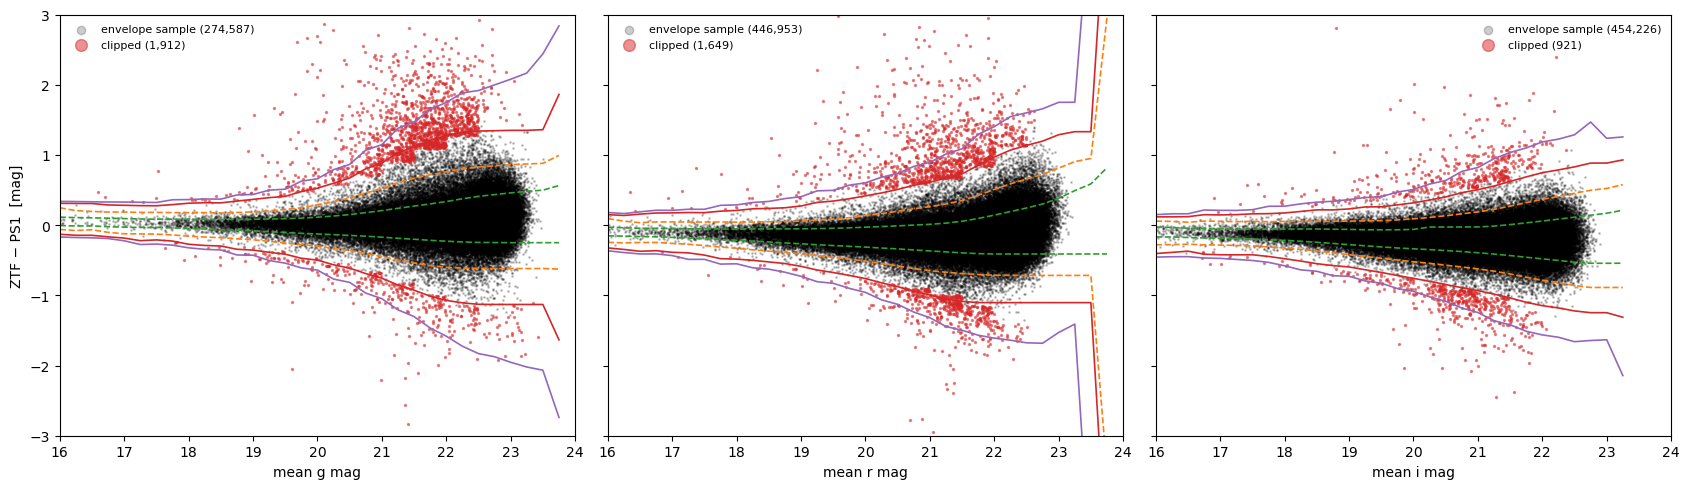

In [ ]:
reach_any = {b: np.logical_or.reduce([reach[name][b] for name in NAMES]) for b in 'gri'}
sample = ff.clip_envelope_sample(src, reach_any, CUTS.envelope_clip_mad)
LEVELS = [(-4, 'C4'), (-3, 'C3'), (-2, 'C1'), (-1, 'C2'), (1, 'C2'), (2, 'C1'), (3, 'C3'), (4, 'C4')]
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
rng = np.random.default_rng(0)
for ax, b in zip(axes, 'gri'):
    two_sided = (src[f'{b}_cat'].values == 0) & reach_any[b]
    mag = (src[f'{b}_ztf_use'].values + src[f'{b}_ps1_use'].values) / 2; d = src[f'{b}_dmag'].values
    show = rng.random(len(src)) < 0.3
    kept, clipped = two_sided & sample[b], two_sided & ~sample[b]
    ax.scatter(mag[kept & show], d[kept & show], s=1, alpha=0.2, color='k', rasterized=True, label=f'envelope sample ({kept.sum():,})')
    ax.scatter(mag[clipped], d[clipped], s=2, alpha=0.5, color='C3', rasterized=True, label=f'clipped ({clipped.sum():,})')
    for n_, c in LEVELS:
        ax.plot(env[b].mag_grid, env[b].get_percentile(env[b].mag_grid, norm.cdf(n_)), color=c, lw=1.2, ls='-' if abs(n_) >= 3 else '--')
    ax.set_xlim(16, 24); ax.set_ylim(-3, 3); ax.set_xlabel(f'mean {b} mag'); ax.legend(frameon=False, fontsize=8, markerscale=6)
axes[0].set_ylabel('ZTF − PS1  [mag]')
plt.tight_layout(); plt.show()

## 8. Interesting

σ = the envelope's signed deviation at the band's mean magnitude (ZTF brighter = negative). A limit supports one
direction only: against the PS1 limit a band can only have brightened (σ ≤ 0, `in_ztf`), against the ZTF limit only
faded (σ ≥ 0, `in_pstarr`); `in_both` takes either sign. Interesting: |σ| > 3 in ≥ 2 bands, ≥ 2 of them the same sign.
There is no S/N cut after this by default (`Cuts.snr_keep` is None): candidates carry `{b}_ztf_snr` / `{b}_ps1_snr`
and the website applies the threshold. Rows: `in_ztf`, `in_pstarr`.

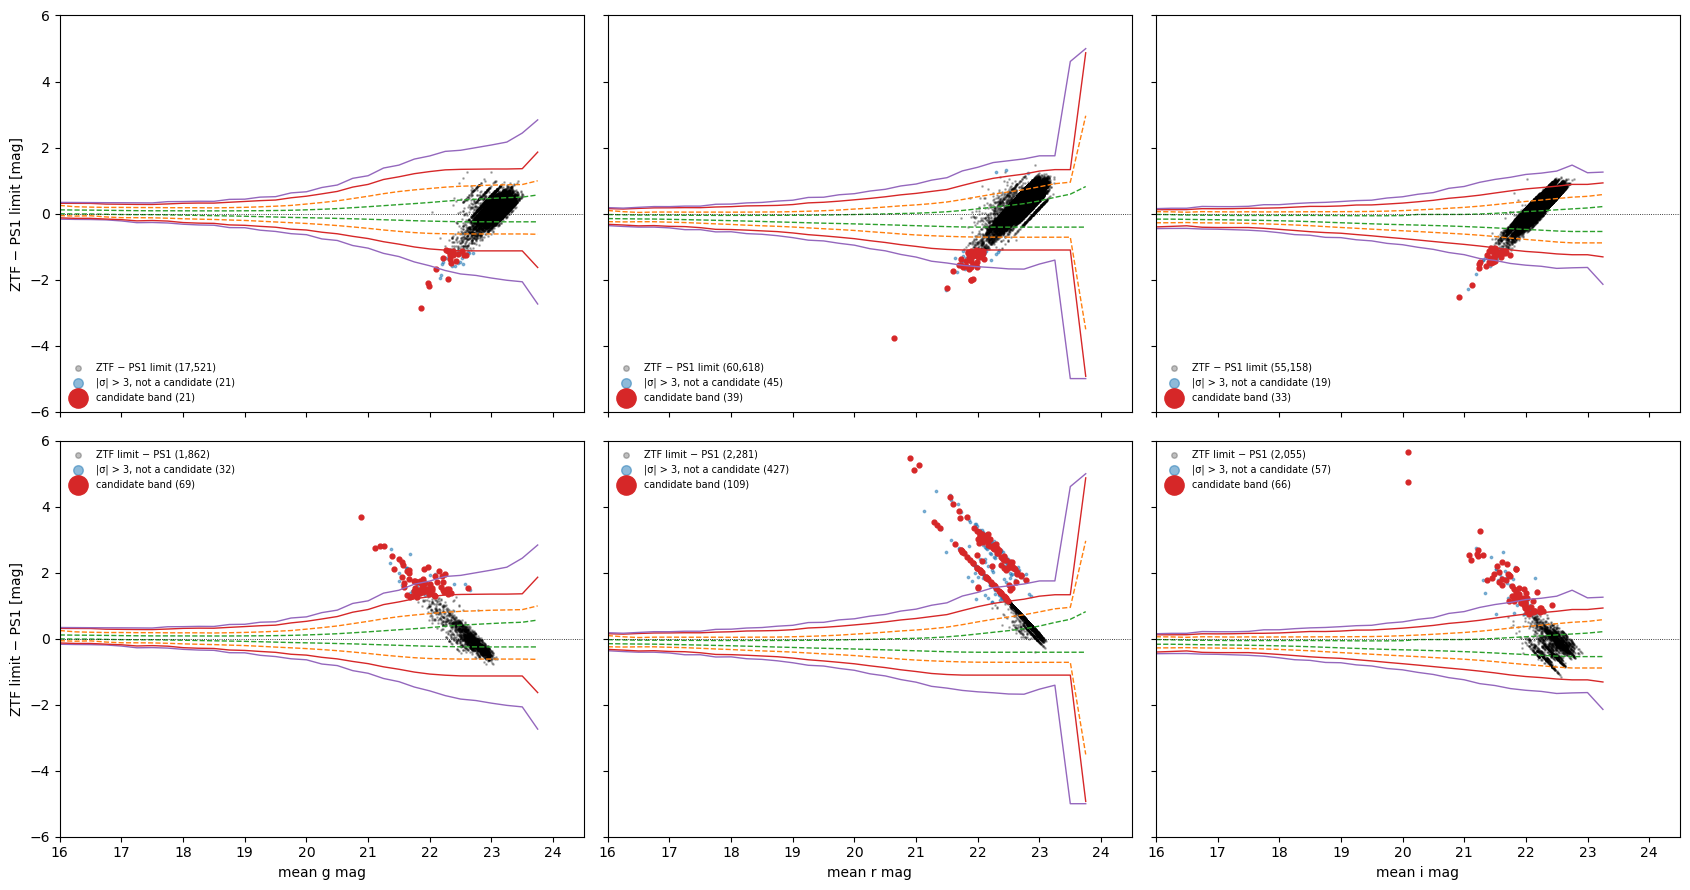

,reach |σ|,|σ| > 3 in ≥ 2 bands,same sign,candidates
catalog,,,,
in_both,470687,403,391,391
in_ztf,62866,44,44,44
in_pstarr,3025,121,121,121


In [ ]:
used = {name: wfs[name].mask(len(wfs[name].steps) - 1) for name in NAMES}
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True, sharey=True)
for row, (k, what) in enumerate(((1, 'ZTF − PS1 limit'), (2, 'ZTF limit − PS1'))):
    name = ff.CATALOG[k]
    for ax, b in zip(axes[row], 'gri'):
        m = (src[f'{b}_cat'].values == k) & reach[name][b]
        mag = (src[f'{b}_ztf_use'].values + src[f'{b}_ps1_use'].values) / 2; d = src[f'{b}_dmag'].values
        big = np.abs(src[f'{b}_sigma'].values) > ff.SIGMA_BOUNDARY
        c = used[name][b]
        ax.scatter(mag[m & ~big], d[m & ~big], s=1, alpha=0.25, color='k', rasterized=True, label=f'{what} ({m.sum():,})')
        ax.scatter(mag[m & big & ~c], d[m & big & ~c], s=3, alpha=0.5, color='C0', rasterized=True, label=f'|σ| > 3, not a candidate ({(m & big & ~c).sum():,})')
        ax.scatter(mag[m & c], d[m & c], s=12, color='C3', label=f'candidate band ({(m & c).sum():,})')
        for n_, col in LEVELS:
            ax.plot(env[b].mag_grid, env[b].get_percentile(env[b].mag_grid, norm.cdf(n_)), color=col, lw=1, ls='-' if abs(n_) >= 3 else '--')
        ax.axhline(0, color='k', lw=0.6, ls=':'); ax.set_xlim(16, 24.5); ax.set_ylim(-6, 6)
        ax.legend(frameon=False, fontsize=7, markerscale=4, loc='lower left' if k == 1 else 'upper left')
        if row == 1: ax.set_xlabel(f'mean {b} mag')
        if b == 'g': ax.set_ylabel(f'{what} [mag]')
plt.tight_layout(); plt.show()
rows = []
for name in NAMES:
    st = wfs[name].stats.set_index('step').objects
    rows.append({'catalog': name, 'reach |σ|': int(st[GAIA]), '|σ| > 3 in ≥ 2 bands': int(st[f'|σ| > {ff.SIGMA_BOUNDARY:.0f} in >= 2 bands']),
                 'same sign': int(st['... >= 2 of them the same sign']), 'candidates': len(cands[name])})
display(pd.DataFrame(rows).set_index('catalog'))

In [ ]:
for name in NAMES:
    cutouts_for_group('interesting', catalog=name)

saved 2 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/interesting/in_both.png
saved 2 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/interesting/in_ztf.png
saved 2 steps → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/interesting/in_pstarr.png


## 9. Results

Flowcharts of the four waterfalls (saved; they are tall), the candidates per catalog, and how many old-pipeline AGN /
TNS sources are candidates now.

In [ ]:
# the flowcharts, saved (they are tall): the shared stage, then one per catalog
for name, title in [('all', f'all objects ({FIELD})')] + [(n, f'{n} ({FIELD})') for n in NAMES]:
    out = f'{REVIEW_DIR}/flowchart_{name}.png'
    wfs[name].flowchart(title).save(out, dpi=90, transparent=False)   # white background
    print(os.path.abspath(out))

/Users/adamboesky/Research/long_transients2/Data/fields/000860/review/flowchart_all.png
/Users/adamboesky/Research/long_transients2/Data/fields/000860/review/flowchart_in_both.png
/Users/adamboesky/Research/long_transients2/Data/fields/000860/review/flowchart_in_ztf.png
/Users/adamboesky/Research/long_transients2/Data/fields/000860/review/flowchart_in_pstarr.png


In [ ]:
display(pd.DataFrame({name: wfs[name].stats.iloc[-1][['objects', *ff.COMBOS]] for name in NAMES}).T)
LT = '/Users/adamboesky/Research/long_transients/Data'
s = pd.read_parquet(f'{LT}/db/sources.parquet', columns=['ra', 'dec', 'fieldid', 'agn_db_matched', 'tns_matched'])
s = s[s.fieldid == FIELD]
cand = pd.concat(cands.values())
for what in ('agn_db_matched', 'tns_matched'):
    k = s[s[what].fillna(False).astype(bool)]
    _, sep, _ = match_coordinates_sky(SkyCoord(k.ra.values * u.deg, k.dec.values * u.deg), SkyCoord(cand.ra.values * u.deg, cand.dec.values * u.deg))
    print(f'{what}: {int((sep.arcsec <= 1.5).sum())} of {len(k)} old-pipeline sources are candidates now')

,objects,gri,gr,gi,ri
in_both,391,54,133,57,147
in_ztf,44,5,11,5,23
in_pstarr,121,2,55,12,52


agn_db_matched: 89 of 148 old-pipeline sources are candidates now
tns_matched: 0 of 4 old-pipeline sources are candidates now


**Every object's record** (`ff.annotate_outcomes`, saved in `objects.parquet`): `outcome` is `candidate`,
`not comparable: <reason>` (never entered a catalog), or `dropped: <step>` (the catalog step at which fewer than two
bands remained). `{b}_dropped_by` is the first step that dropped band b, shared stage included, or `kept`; a band also
counts as dropped at the step where its object fell below two bands. Rows below are in pipeline order.
`ff.explain(FIELD, ra, dec, D)` prints one object's story from the last saved run (`python -m Source_Analysis.filter_field run 860` writes it).

In [ ]:
cat_name = src.catalog.map({**ff.CATALOG, -1: ff.NOT_COMPARABLE}).rename('catalog')
longest = max(NAMES, key=lambda n: len(wfs[n].steps))                  # in_pstarr: every catalog step, in chain order
steps = list(dict.fromkeys(wfs['all'].steps + wfs[longest].steps + [s for name in NAMES for s in wfs[name].steps]))
order = ['candidate'] + [f'not comparable: {r}' for r in ff.REASONS] + [f'dropped: {s}' for s in steps]
t = pd.crosstab(src.outcome.astype(str).rename('outcome'), cat_name)[[*NAMES, ff.NOT_COMPARABLE]]
display(t.reindex([o for o in order if o in t.index] + [o for o in t.index if o not in order]))
db = pd.DataFrame({f'{b} dropped by': src[f'{b}_dropped_by'].astype(str).value_counts() for b in 'gri'})
display(db.reindex([s for s in steps + [ff.KEPT] if s in db.index]).fillna(0).astype(int))

catalog,in_both,in_ztf,in_pstarr,not comparable
outcome,,,,
candidate,391,44,121,0
not comparable: fewer than two measured bands,0,0,0,4544688
not comparable: no comparable band,0,0,0,726391
not comparable: one comparable band,0,0,0,710262
not comparable: one two-sided band,0,0,0,389536
not comparable: mixed one-sided kinds,0,0,0,64104
dropped: outside bright-star masks,35040,29440,3116,0
"dropped: no other object within 3""",0,44566,13674,0
dropped: outside every brighter object's Kron aperture,0,7281,832,0


,g dropped by,r dropped by,i dropped by
>= 2 bands: measured by ZTF or PS1,4768950,4605547,4642958
ZTF image covers the position,180404,172134,189298
ZTF: DAOPhot flags = 0,2791,3098,3110
ZTF: > 5 px from a masked pixel,32985,37018,25739
extended: ZTF Kron aperture <= 10% masked,56294,61552,65092
PS1: not in a flagged polar skycell,13758,15071,14614
PS1: residual sky <= 1e-07,14465,39215,28180
PS1: stack nFrames >= 4,48236,43461,18282
PS1: not DEFECT,3344,3877,5445
PS1: not PEAK_ON_SPIKE,481,612,693


In [ ]:
# one candidate's record, as ff.explain prints it from a saved run
ex = cands['in_ztf'].index[0] if len(cands['in_ztf']) else cands['in_both'].index[0]
display(src.loc[ex, ff.EXPLAIN_COLS].to_frame().T)

,ra,dec,ztf_idx,ps1_idx,catalog,catalog_reason,outcome,g_point,g_ztf_status,g_ps1_status,g_ztf_psf,g_ps1_psf,g_ztf_snr,g_ps1_snr,g_sigma,g_dropped_by,r_ztf_status,r_ps1_status,r_ztf_psf,r_ps1_psf,r_ztf_snr,r_ps1_snr,r_sigma,r_dropped_by,i_ztf_status,i_ps1_status,i_ztf_psf,i_ps1_psf,i_ztf_snr,i_ps1_snr,i_sigma,i_dropped_by
57582,165.709847,73.598165,57582,-1,1,,candidate,True,U,U,NaN,NaN,NaN,NaN,NaN,>= 2 bands: measured by ZTF or PS1,D,U,21.022,NaN,8.057716,NaN,-4.170579,kept,D,U,20.913,NaN,9.444066,NaN,-3.49058,kept


Highest-|σ| candidates per catalog: ZTF reference (left) and PS1 stack (right) in the band with the largest |σ|
among the bands that make them candidates, 30″. Below: band, mean mag, Δ = ZTF − PS1, σ per band.

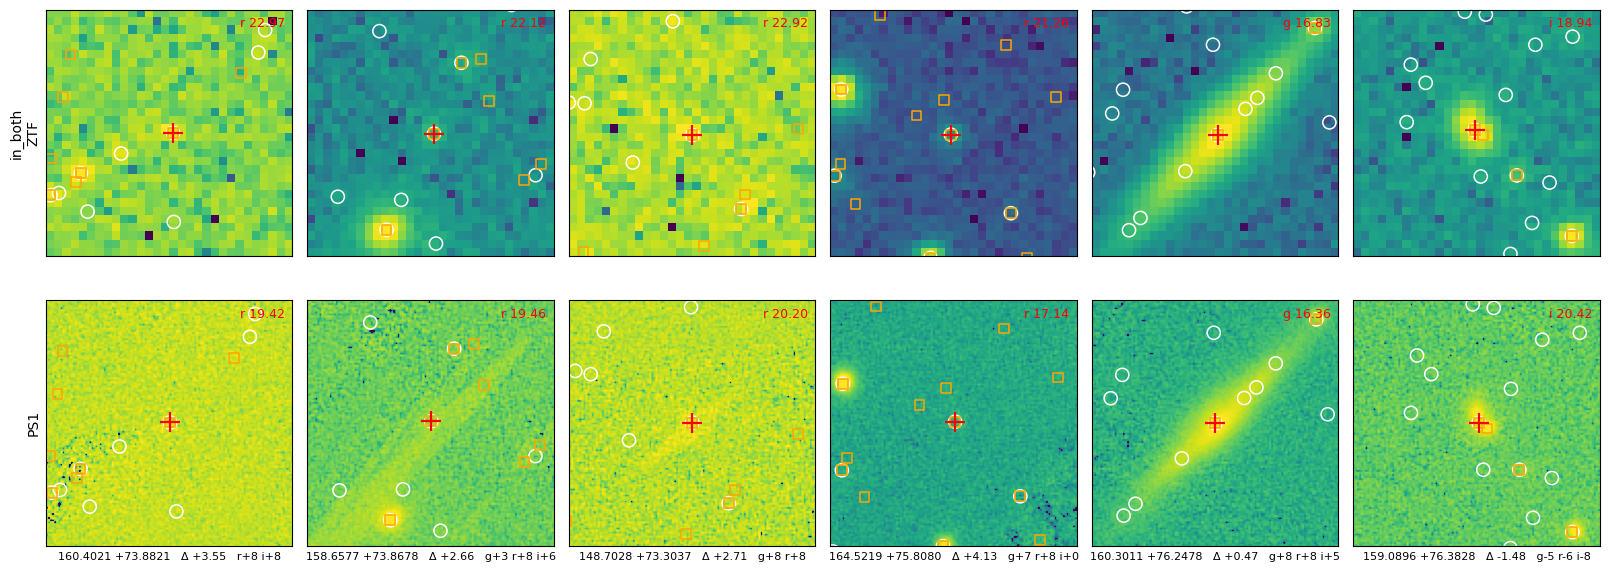

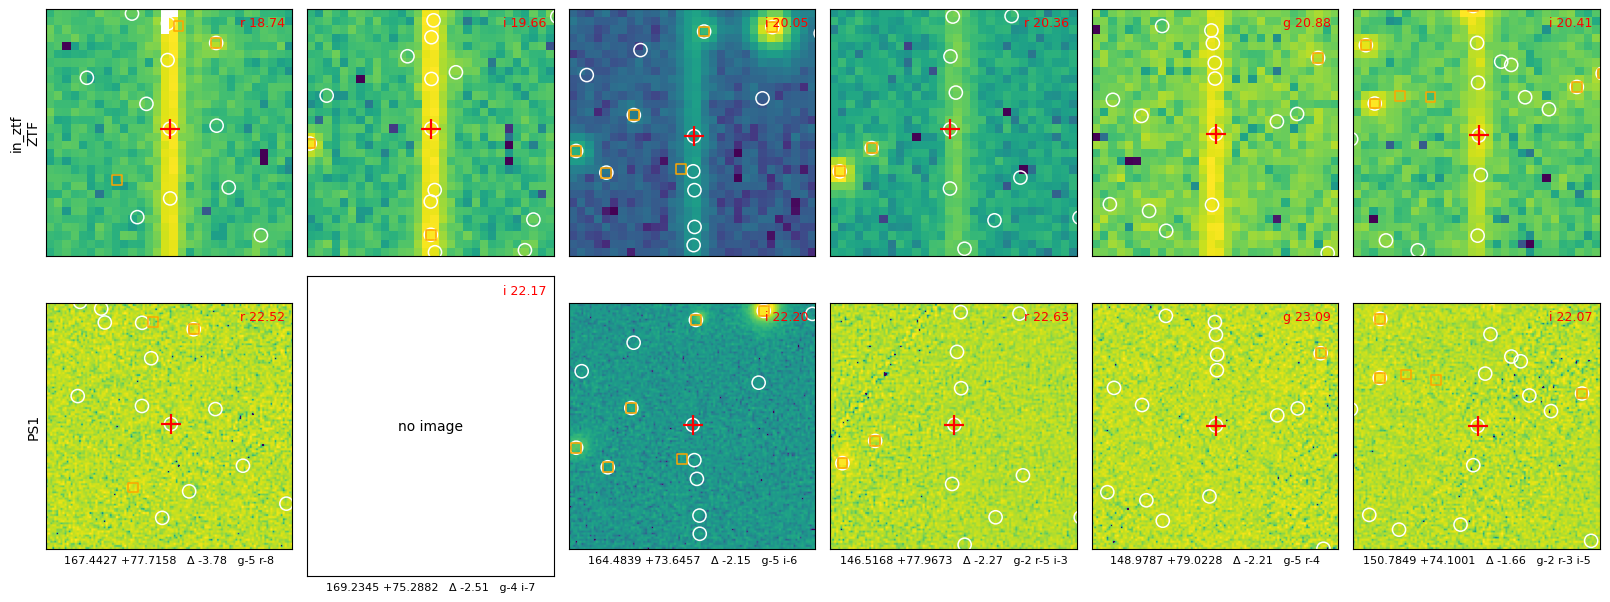

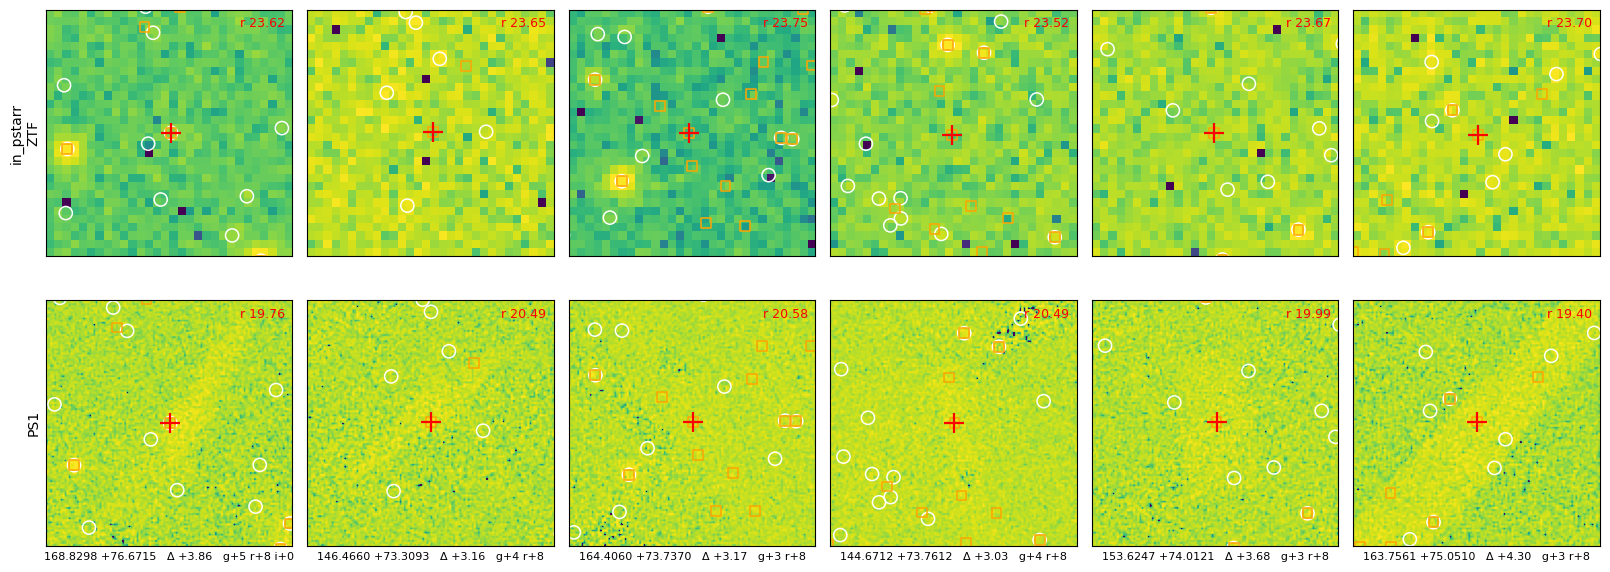

In [ ]:
# highest-|σ| candidates per catalog: ZTF reference over PS1 stack in the band with the largest |σ| among the bands
# that make them candidates; each stamp shows the magnitude actually compared (measurement or limit), the caption Δ and σ
N_SHOW = 6
for name in NAMES:
    cand = cands[name]
    if len(cand) == 0:
        print(f'{name}: no candidates'); continue
    abs_sig = np.column_stack([np.where(used[name][b][cand.index], np.abs(cand[f'{b}_sigma'].values), -1) for b in 'gri'])
    cand = cand.assign(best_band=np.array(list('gri'))[abs_sig.argmax(axis=1)], max_abs_sigma=abs_sig.max(axis=1))
    rows = cand.nlargest(N_SHOW, 'max_abs_sigma')
    files = ps1_filenames(rows[['ra', 'dec']]).round({'ra': 6, 'dec': 6}).groupby(['ra', 'dec', 'filter']).filename.first()
    fig, axes = plt.subplots(2, N_SHOW, figsize=(2.7 * N_SHOW, 6.4), squeeze=False)
    for j, (_, r) in enumerate(rows.iterrows()):
        b = r.best_band
        stamp_pair(axes[0, j], axes[1, j], r, b, files, 30)
        for ax, m in ((axes[0, j], r[f'{b}_ztf_use']), (axes[1, j], r[f'{b}_ps1_use'])):      # the compared magnitudes replace the PSF ones
            for t in list(ax.texts):
                if t.get_position() == (0.97, 0.97): t.remove()
            ax.text(0.97, 0.97, f'{b} {m:.2f}', color='red', fontsize=9, ha='right', va='top', transform=ax.transAxes)
        axes[1, j].set_xlabel(f"{r.ra:.4f} {r.dec:+.4f}   Δ {r[f'{b}_dmag']:+.2f}   " + ' '.join(f"{x}{r[f'{x}_sigma']:+.0f}" for x in 'gri' if np.isfinite(r[f'{x}_sigma'])), fontsize=8)
    for j in range(len(rows), N_SHOW): axes[0, j].axis('off'); axes[1, j].axis('off')
    axes[0, 0].set_ylabel(f'{name}\nZTF', fontsize=10); axes[1, 0].set_ylabel('PS1', fontsize=10)
    plt.tight_layout(); plt.show()